<a href="https://colab.research.google.com/github/PolF805/tsm-nvda-quant-monte-carlo/blob/main/quant_analysis_gbm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import yfinance as yf
import pandas as pd
import sqlite3 as sql

import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
from scipy.stats import norm


In [32]:
def load_dataset(ticker, start_date, end_date, index=None):
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=index)
  return data

start = '2021-10-01'
end   = '2026-10-01'

features = ['Close', 'Volume']

TSM_uncleaned = load_dataset('TSM', start, end, index=False)
NVDA_uncleaned = load_dataset('NVDA', start, end, index=False)


/tmp/ipykernel_3929/2421422142.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=index)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_3929/2421422142.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=index)
[*********************100%***********************]  1 of 1 completed


In [33]:
def clean_data(data, feature=None):
  display(data.describe(include='all'))
  data = data.copy()

  data = (
      data.drop_duplicates(subset=['Date'])
      if 'Date' in data.columns
      else data[~data.index.duplicated()]
  )

  if feature is not None:
    data = data[feature]
  data = data.ffill().dropna()

  return data.copy()


feature = ['Close']

TSM_copy = clean_data(TSM_uncleaned, feature)
NVDA_copy = clean_data(NVDA_uncleaned, feature)

,Close,High,Low,Open,Volume
count,1254.000000,1254.000000,1254.000000,1254.000000,1.254000e+03
mean,175.036332,177.413608,172.574405,175.100069,1.288940e+07
std,108.411907,110.040170,106.646604,108.478502,6.517532e+06
min,56.759594,57.333970,55.959236,56.458283,2.753900e+06
25%,89.011370,89.786779,87.980531,89.163022,9.032225e+06
50%,134.407501,136.850049,132.842147,133.873764,1.144470e+07
75%,224.633892,225.881708,220.979205,224.024763,1.487555e+07
max,476.292267,477.718434,463.925421,474.816186,6.866750e+07


,Close,High,Low,Open,Volume
count,1254.000000,1254.000000,1254.000000,1254.000000,1.254000e+03
mean,94.566075,96.124739,92.924175,94.605237,3.673440e+08
std,69.805952,70.799299,68.851769,69.906917,1.942172e+08
min,11.186728,11.692904,10.774211,10.931645,6.552850e+07
25%,26.450738,26.938523,26.103680,26.471002,1.929811e+08
50%,87.382343,88.802293,85.751989,87.216681,3.561785e+08
75%,157.543659,158.309280,155.403906,157.336662,4.911212e+08
max,235.202393,236.000556,229.373344,232.849448,1.543911e+09


In [34]:
conn = sql.Connection('stocks_data.db')
cursor = conn.cursor()

TSM_copy.to_sql('tsm', conn, if_exists='replace')
NVDA_copy.to_sql('nvda', conn, if_exists='replace')

query = """
DROP VIEW IF EXISTS paired_close_data;

CREATE VIEW paired_close_data AS
SELECT
  t.Date AS Date,
  t.Close AS tsm_close,
  LAG(t.Close, 1) OVER(
  ORDER BY t.Date ASC) AS tsm_lag,
  n.Close AS nvda_close,
  LAG(n.Close, 1) OVER(
  ORDER BY n.Date ASC) AS nvda_lag
FROM tsm t
INNER JOIN nvda n ON
  t.Date = n.Date;
"""

cursor.executescript(query)
conn.commit()

In [35]:
df = pd.read_sql('SELECT * FROM paired_close_data;', conn, index_col='Date', parse_dates=['Date']).dropna()
cursor.close()
conn.close()

display(df.head(5))


,tsm_close,tsm_lag,nvda_close,nvda_lag
Date,,,,
2021-10-04,100.637337,102.982040,19.645470,20.651041
2021-10-05,100.858894,100.637337,20.361317,19.645470
2021-10-06,100.932739,100.858894,20.609224,20.361317
2021-10-07,102.308167,100.932739,20.982582,20.609224
2021-10-08,101.578918,102.308167,20.739651,20.982582


In [36]:
def log_return(df, prefix):
  df[f"{prefix}_log_return"] = np.log(df[f"{prefix}_close"]/df[f"{prefix}_lag"])
  return df

def moving_average(df, prefix, window=None, min_periods=None):
  df[f"{prefix}_{window}_ma"] = df[f"{prefix}_close"].rolling(window, min_periods).mean()
  return df

def mean_sigma(df, col, annualize=False, annual=252):
  mean = df[col].mean()
  sigma = df[col].std(ddof=1)
  if annualize:
    return mean * annual, sigma * np.sqrt(annual)
  return mean, sigma


prefixes = ['tsm', 'nvda']
for p in prefixes:
  df = log_return(df, p)
  df = moving_average(df, p, window=50, min_periods=1)
  df = moving_average(df, p, window=252, min_periods=1)

tsm_daily_mean, tsm_daily_sigma = mean_sigma(df, 'tsm_log_return')
nvda_daily_mean, nvda_daily_sigma = mean_sigma(df, 'nvda_log_return')

train_df = df.loc[:'2025-09-30'].copy()
tsm_annual_mean_4y, tsm_annual_sigma_4y   = mean_sigma(train_df, 'tsm_log_return', annualize=True)
nvda_annual_mean_4y, nvda_annual_sigma_4y = mean_sigma(train_df, 'nvda_log_return', annualize=True)


def extract_feature(df, prefix):
  features = [f"{prefix}_close", f"{prefix}_lag", f"{prefix}_log_return", f"{prefix}_50_ma", f"{prefix}_252_ma"]
  return df[features].copy()


TSM = extract_feature(df, 'tsm')
NVDA = extract_feature(df, 'nvda')


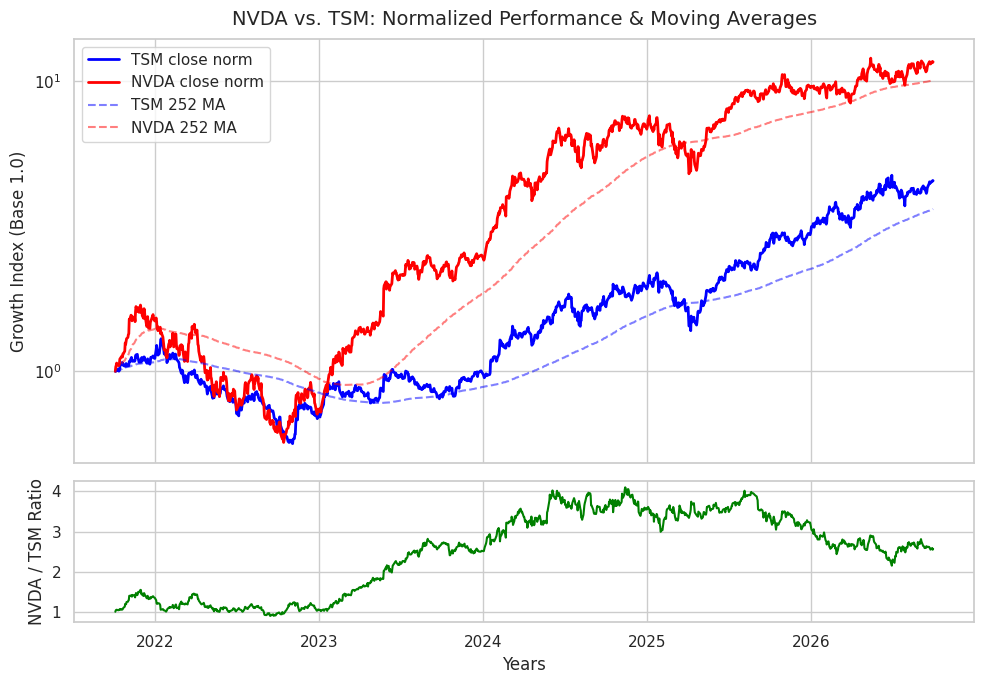

In [37]:

TSM['tsm_norm'] = TSM['tsm_close'] / TSM['tsm_close'].iloc[0]
NVDA['nvda_norm'] = NVDA['nvda_close'] / NVDA['nvda_close'].iloc[0]

TSM['tsm_252_ma_norm'] = TSM['tsm_252_ma'] / TSM['tsm_close'].iloc[0]
NVDA['nvda_252_ma_norm'] = NVDA['nvda_252_ma'] / NVDA['nvda_close'].iloc[0]

perf_ratio = NVDA['nvda_norm'] / TSM['tsm_norm']



sns.set_theme(style='whitegrid')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})


sns.lineplot(data=TSM, ax=ax1, x=df.index, y='tsm_norm', linewidth=2, color='blue', label="TSM close norm")
sns.lineplot(data=NVDA, ax=ax1, x=df.index, y='nvda_norm', linewidth=2, color='red', label='NVDA close norm')


sns.lineplot(data=TSM, ax=ax1, x=df.index, y='tsm_252_ma_norm', color='blue', linestyle="--", alpha=0.5, label="TSM 252 MA")
sns.lineplot(data=NVDA, ax=ax1, x=df.index, y='nvda_252_ma_norm', color='red', linestyle="--", alpha=0.5, label="NVDA 252 MA")

ax1.set_yscale("log")
ax1.set_ylabel("Growth Index (Base 1.0)")
ax1.set_title("NVDA vs. TSM: Normalized Performance & Moving Averages", fontsize=14, pad=10)
ax1.legend(loc="upper left")


ax2.plot(df.index, perf_ratio, color='green', linewidth=1.5)
ax2.set_ylabel("NVDA / TSM Ratio")
ax2.set_xlabel('Years')

plt.tight_layout()
plt.show()


In [38]:
X = NVDA['nvda_log_return']
Y = TSM['tsm_log_return']


X_constant = sm.add_constant(X)
X_constant.head(3)
model = sm.OLS(Y, X_constant)
reg_result = model.fit()

print(reg_result.summary())

coeff = reg_result.params
alpha = coeff['const']
beta = coeff['nvda_log_return']

                            OLS Regression Results                            
Dep. Variable:         tsm_log_return   R-squared:                       0.470
Model:                            OLS   Adj. R-squared:                  0.469
Method:                 Least Squares   F-statistic:                     1108.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          1.44e-174
Time:                        11:27:16   Log-Likelihood:                 3287.6
No. Observations:                1253   AIC:                            -6571.
Df Residuals:                    1251   BIC:                            -6561.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0002      0.000     

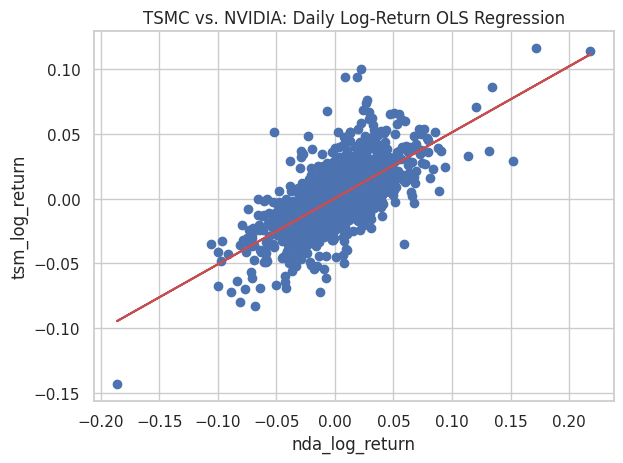

In [39]:
plt.plot(X, Y, 'o')
plt.plot(X, alpha+beta*X, 'r')
plt.title("TSMC vs. NVIDIA: Daily Log-Return OLS Regression")
plt.ylabel("tsm_log_return")
plt.xlabel("nda_log_return")
plt.tight_layout()
plt.show()


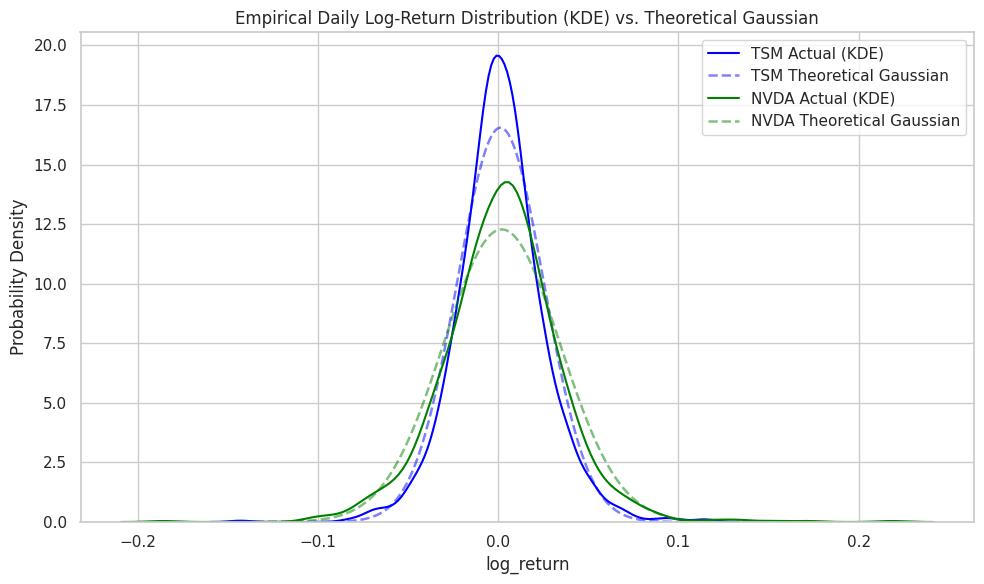

In [40]:
plt.figure(figsize=(10,6))
x_value = np.linspace(-0.15, 0.15, 1250)

tsm_pdf = norm.pdf(x=x_value, loc=tsm_daily_mean, scale=tsm_daily_sigma)
nvda_pdf = norm.pdf(x=x_value, loc=nvda_daily_mean, scale=nvda_daily_sigma)

sns.kdeplot(x=Y, color='blue', label='TSM Actual (KDE)')
plt.plot(x_value, tsm_pdf, color='blue', linestyle='--', alpha=0.5, linewidth=1.8, label='TSM Theoretical Gaussian')

sns.kdeplot(x=X, color='green', label='NVDA Actual (KDE)')
plt.plot(x_value, nvda_pdf, color='green', linestyle='--', alpha=0.5, linewidth=1.8, label='NVDA Theoretical Gaussian')


plt.xlabel("log_return")
plt.ylabel("Probability Density")
plt.title("Empirical Daily Log-Return Distribution (KDE) vs. Theoretical Gaussian")
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
def simulated_gbm(S0, sigma, mu, n_simulation, T=1.0, N=252, Z=None):
  dt = T/N
  if Z is None:
    Z = np.random.normal(loc=0, scale=1, size=(N, n_simulation))

  drift = (mu - 0.5 * (sigma**2)) * dt
  shock = sigma * np.sqrt(dt) * Z
  daily_return = np.exp(drift + shock)

  paths = np.zeros((N + 1, n_simulation))
  paths[0] = S0
  paths[1:] = S0 * np.cumprod(daily_return, axis=0)
  return paths


def plot_gbm(ax, paths, title, actual_path=None):
    ax.plot(paths, alpha=0.15, linewidth=0.5, color='gray')
    ax.plot(paths.mean(axis=1), color='red', linewidth=2, label='Sim Mean Path')
    ax.plot(np.percentile(paths, 5, axis=1), color='blue', linestyle='--', linewidth=1.8, label='90% CI (5th / 95th Pct)')
    ax.plot(np.percentile(paths, 95, axis=1), color='blue', linestyle='--', linewidth=1.8)

    if actual_path is not None:
        ax.plot(actual_path, color='black', linewidth=2.5, label='Actual Year 5 (Test)')

    ax.set_title(title)
    ax.set_xlabel("Trading Days (Year 5)")
    ax.set_ylabel("Price ($)")
    ax.legend(loc="upper left")

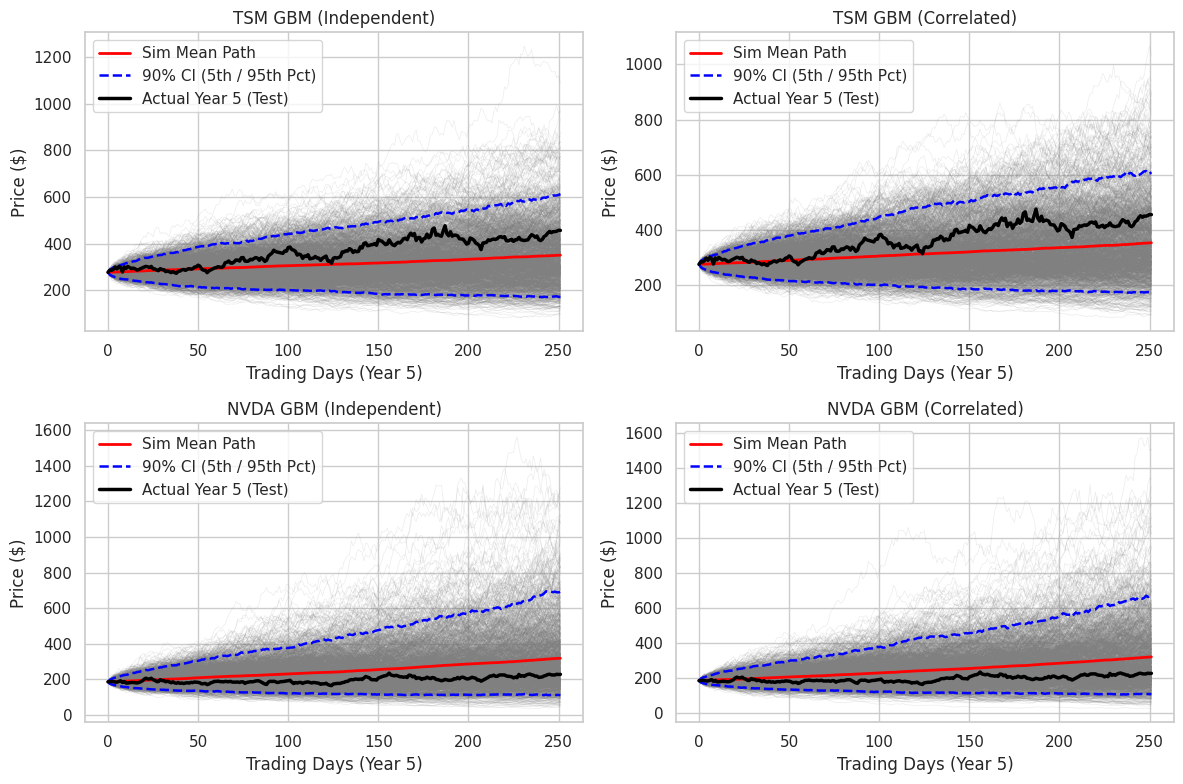

In [42]:
np.random.seed(42)

# Split 4Y Train (Oct 2021 - Sep 2025) and 1Y Test (Oct 2025 - Oct 2026)
train_tsm = TSM.loc[:'2025-09-30'].copy()
test_tsm  = TSM.loc['2025-10-01':].copy()

train_nvda = NVDA.loc[:'2025-09-30'].copy()
test_nvda  = NVDA.loc['2025-10-01':].copy()

annual = 252
N = len(test_tsm)
n_sim = 1500


rho_4y = train_nvda['nvda_log_return'].corr(train_tsm['tsm_log_return'], method='pearson')

eps1 = np.random.normal(0, 1, size=(N, n_sim))
eps2 = np.random.normal(0, 1, size=(N, n_sim))

Z1 = eps1
Z2 = rho_4y * eps1 + np.sqrt(1 - rho_4y**2) * eps2

# Starting price S0 = last close price of Year 4 (.iloc[-1])
tsm_S0  = train_tsm['tsm_close'].iloc[-1]
nvda_S0 = train_nvda['nvda_close'].iloc[-1]

# Model A: Independent paths
tsm_ind_path  = simulated_gbm(tsm_S0, sigma=tsm_annual_sigma_4y, mu=tsm_annual_mean_4y, n_simulation=n_sim, N=N)
nvda_ind_path = simulated_gbm(nvda_S0, sigma=nvda_annual_sigma_4y, mu=nvda_annual_mean_4y, n_simulation=n_sim, N=N)

# Model B: Correlated paths
S1 = simulated_gbm(tsm_S0, sigma=tsm_annual_sigma_4y, mu=tsm_annual_mean_4y, n_simulation=n_sim, N=N, Z=Z1)
S2 = simulated_gbm(nvda_S0, sigma=nvda_annual_sigma_4y, mu=nvda_annual_mean_4y, n_simulation=n_sim, N=N, Z=Z2)


# plot
tsm_actual_path  = np.insert(test_tsm['tsm_close'].values, 0, tsm_S0)
nvda_actual_path = np.insert(test_nvda['nvda_close'].values, 0, nvda_S0)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))

plot_gbm(ax1, tsm_ind_path,  "TSM GBM (Independent)",  actual_path=tsm_actual_path)
plot_gbm(ax2, S1,            "TSM GBM (Correlated)",   actual_path=tsm_actual_path)
plot_gbm(ax3, nvda_ind_path, "NVDA GBM (Independent)", actual_path=nvda_actual_path)
plot_gbm(ax4, S2,            "NVDA GBM (Correlated)",  actual_path=nvda_actual_path)

plt.tight_layout()
plt.show()

In [43]:

tsm_sim_final  = S1[-1, :].mean()                 # Avg simulated price on last day of Year 5
tsm_real_final = test_tsm['tsm_close'].iloc[-1]   # Actual price on last day of Year 5

nvda_sim_final  = S2[-1, :].mean()
nvda_real_final = test_nvda['nvda_close'].iloc[-1]

print("--- 1. Final Day Price (End of Year 5) ---")
print(f"TSM  -> Sim: ${tsm_sim_final:.2f}, Real: ${tsm_real_final:.2f}, pct_diff: {((tsm_real_final/tsm_sim_final)-1)*100:.2f}%")
print(f"NVDA -> Sim: ${nvda_sim_final:.2f}, Real: ${nvda_real_final:.2f}, pct_diff: {((nvda_real_final/nvda_sim_final)-1)*100:.2f}%")


tsm_sim_ret  = np.log(S1[-1, :] / S1[0, :]).mean()
tsm_real_ret = np.log(tsm_real_final / tsm_S0)

nvda_sim_ret  = np.log(S2[-1, :] / S2[0, :]).mean()
nvda_real_ret = np.log(nvda_real_final / nvda_S0)

print("\n--- 2. Total 1-Year Log Return ---")
print(f"TSM  -> Sim Mean Return: {tsm_sim_ret*100:.2f}%, Real Return: {tsm_real_ret*100:.2f}%")
print(f"NVDA -> Sim Mean Return: {nvda_sim_ret*100:.2f}%, Real Return: {nvda_real_ret*100:.2f}%")



tsm_sim_vol  = (np.diff(np.log(S1), axis=0).std(axis=0, ddof=1) * np.sqrt(252)).mean()
tsm_real_vol = test_tsm['tsm_log_return'].std(ddof=1) * np.sqrt(252)

nvda_sim_vol  = (np.diff(np.log(S2), axis=0).std(axis=0, ddof=1) * np.sqrt(252)).mean()
nvda_real_vol = test_nvda['nvda_log_return'].std(ddof=1) * np.sqrt(252)

print("\n--- 3. Annualized Volatility (Sigma) ---")
print(f"TSM  -> Sim Vol: {tsm_sim_vol*100:.2f}%, Real Vol: {tsm_real_vol*100:.2f}%")
print(f"NVDA -> Sim Vol: {nvda_sim_vol*100:.2f}%, Real Vol: {nvda_real_vol*100:.2f}%")

--- 1. Final Day Price (End of Year 5) ---
TSM  -> Sim: $354.37, Real: $456.19, pct_diff: 28.73%
NVDA -> Sim: $322.15, Real: $228.38, pct_diff: -29.11%

--- 2. Total 1-Year Log Return ---
TSM  -> Sim Mean Return: 17.63%, Real Return: 50.12%
NVDA -> Sim Mean Return: 39.52%, Real Return: 20.45%

--- 3. Annualized Volatility (Sigma) ---
TSM  -> Sim Vol: 37.85%, Real Vol: 40.13%
NVDA -> Sim Vol: 54.56%, Real Vol: 37.60%
